<h1 align="center">Física Computacional.</h1>
<h1 align="center">Semestre 2027-1</h1>

<h2>Franco Olvera Ángel Jesús </h2> 

---


<h1 align="center">Programación para la física computacional</h1> 

## Práctica 4.  Métodos de integración numérica

---

### **EJERCICIOS**:

$\;$

### **1.  Regla del Trapecio** 
Escribe un programa para hacer lo siguiente: $\\$
(a) Lee los datos y, usando la regla del trapecio, calcula a partir de ellos la distancia aproximada recorrida por la partícula en la dirección x como una función del tiempo. $\\$
(b) Extiende tu programa para hacer una grafica que muestre, en el mismo gráfico, tanto la curva de velocidad original como la distancia recorrida como una función del tiempo.
#### 

In [1]:
import numpy as np
import matplotlib.pyplot as plt


Como ya conocemos los datos completos, podemos usar la siguiente expresión, la cual sigue siendo la regla del trapecio:

$$
x_i = \frac{1}{2}(v_i + v_{i-1})\Delta t + x_{i-1}
$$


Text(0, 0.5, 'Velocidad[m/s]')

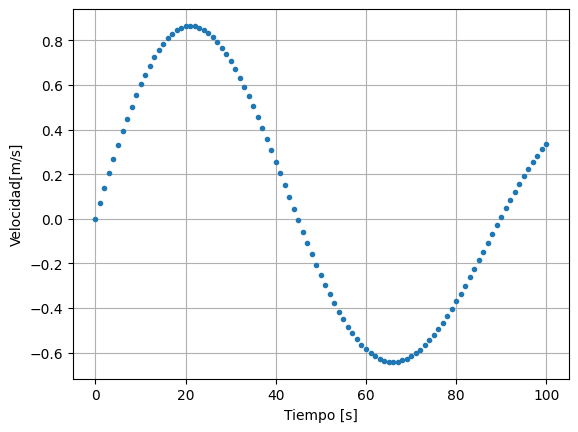

In [7]:
datos = np.loadtxt("velocidades.txt")    #Abrir el archivo de datos

#Dividimos los datos en dos listas
t = datos[:,0]
vel= datos[:,1]

x = np.zeros(len(t)) #Creamos un arreglo de ceros del tamaño de t

for i in np.arange(1, len(t)):
    dt = t[i] - t[i-1] #El tiempo siempre cambia en +1, i.e, dt=1
    trapecio = 0.5 * (vel[i] - vel[i-1]) * dt
    
    x[i] = trapecio + x[i-1] #Usando la expresion de arriba



plt.plot(t, vel, ".")
plt.grid()
#Ponemos nombres a los ejes
plt.xlabel("Tiempo [s]")
plt.ylabel("Velocidad[m/s]")


### 
b) Extiende tu programa para hacer una grafica que muestre, en el mismo gráfico, tanto la curva de velocidad original como la distancia recorrida como una funcion del tiempo.
#### 

In [8]:
import numpy as np
import matplotlib.pyplot as plt

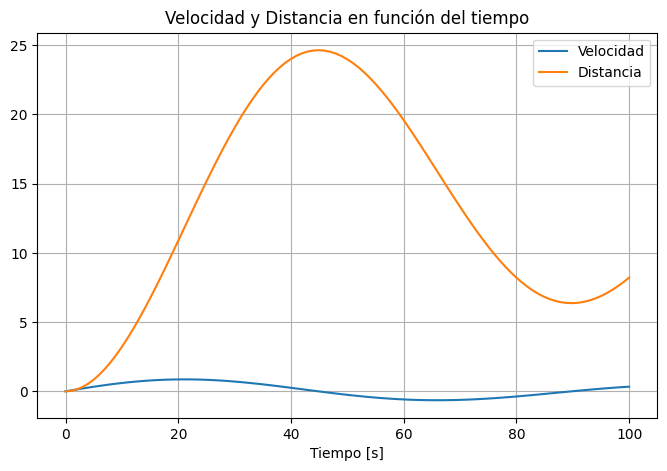

In [26]:
#Reutilizamos el código anterior.

datos = np.loadtxt("velocidades.txt")    #Abrir el archivo de datos

#Dividimos los datos en dos listas
t = datos[:,0]
vel= datos[:,1]

x = np.zeros(len(t)) #Creamos un arreglo de ceros del tamaño de t

for i in np.arange(1, len(t)):
    dt = t[i] - t[i-1] #El tiempo siempre cambia en +1, i.e, dt=1
    trapecio = 0.5 * (vel[i] + vel[i-1]) * dt
    
    x[i] = trapecio + x[i-1] #Usando la expresion de arriba


plt.figure(figsize=(8,5)) #Hacemos más grande la gráfica para que se vea mejor la velocidad.


plt.plot(t, vel, label="Velocidad")
plt.plot(t, x, label="Distancia")

plt.grid()
plt.title('Velocidad y Distancia en función del tiempo')
#Ponemos nombres a los ejes
plt.xlabel("Tiempo [s]")
plt.ylabel("") #No supe que nombre ponerle la vdd

plt.legend()

### **2. El límite de difracción de un telescopio** 


## Responde a las siguientes preguntas:

(a) Escribe una funcion $J(m,x)$ que calcule el valor de $Jm(x)$ usando la regla de Simpson con N = 1000 puntos. Utiliza dicha funcion en un programa para graficar, en un solo gráfico, las funciones de Bessel  $J_0$, $J_1$ y $J_2$ como una funcion de x (de x = 0 a x = 20).


In [27]:
import numpy as np
import matplotlib.pyplot as plt

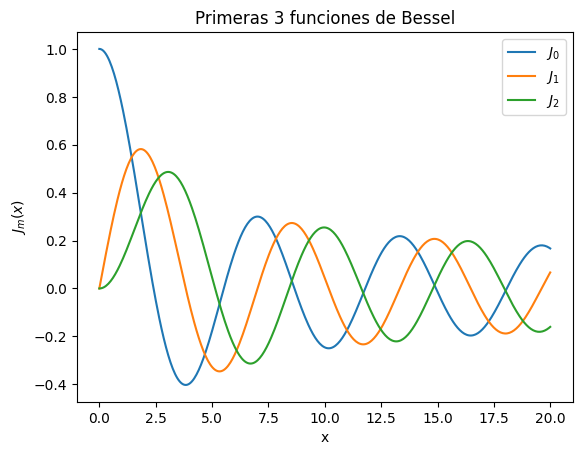

In [63]:
#Definimos la regla de simpson:

def J_simp(m,x):
    N=1000
    a = 0.0
    b = np.pi
    h= (b-a)/N
    theta= np.linspace(a,b, N+1)

    #definimos la funcion que queremos integrsr:
    f = np.cos(m*theta - x* np.sin(theta))

    #Separamos índices pares e impares
    impares = np.sum(f[1:-1:2])
    pares = np.sum(f[2:-1:2])

    #Calculamos la integral:
    int = (h/3) * (f[0]+ 4*impares + 2*pares + f[N])

    return (1/np.pi) * int

#Tomamos los valores de x=0 a x=20
xvalor= np.linspace(0,20,400)
#Calculamos las funcioens de Bessel:
J0 = [J_simp(0, x) for x in xvalor]
J1 = [J_simp(1, x) for x in xvalor]
J2 = [J_simp(2, x) for x in xvalor]
#Hacemos la gráfica
plt.plot(xvalor, J0, label= "$J_0$")
plt.plot(xvalor, J1, label= "$J_1$")
plt.plot(xvalor, J2,  label= "$J_2$")


plt.title("Primeras 3 funciones de Bessel")
plt.xlabel ("x")
plt.ylabel ("$J_m (x)$")
plt.legend()

**(b)** Compara tus resultados con los proporcionados con la biblioteca de scipy que implementa la regla de Simpson




In [64]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

In [65]:
help(scipy)

Help on package scipy:

NAME
    scipy

DESCRIPTION
    SciPy: A scientific computing package for Python

    Documentation is available in the docstrings and
    online at https://docs.scipy.org/doc/scipy/

    Subpackages
    -----------
    ::

     cluster                      --- Vector Quantization / Kmeans
     constants                    --- Physical and mathematical constants and units
     datasets                     --- Dataset methods
     differentiate                --- Finite difference differentiation tools
     fft                          --- Discrete Fourier transforms
     fftpack                      --- Legacy discrete Fourier transforms
     integrate                    --- Integration routines
     interpolate                  --- Interpolation Tools
     io                           --- Data input and output
     linalg                       --- Linear algebra routines
     ndimage                      --- N-D image package
     odr                          -

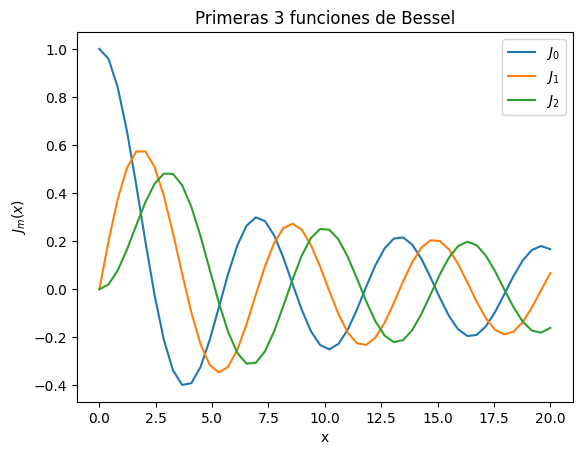

In [76]:
#Definimos la funcion de bessel
def J_scipy(m,x):
    theta = np.linspace(0,np.pi,1001)
    f = np.cos(m*theta - x* np.sin(theta))

    integral = scipy.integrate.simpson(f, x=theta)
    return (1/np.pi)*integral


#Tomamos los valores de x=0 a x=20
xvalor= np.linspace(0,20)
#Calculamos las funcioens de Bessel:
J0 = [J_simp(0, x) for x in xvalor]
J1 = [J_simp(1, x) for x in xvalor]
J2 = [J_simp(2, x) for x in xvalor]
#Hacemos la gráfica
plt.plot(xvalor, J0, label= "$J_0$")
plt.plot(xvalor, J1, label= "$J_1$")
plt.plot(xvalor, J2,  label= "$J_2$")


plt.title("Primeras 3 funciones de Bessel")
plt.xlabel ("x")
plt.ylabel ("$J_m (x)$")
plt.legend()

(c) Escribe un segundo programa que haga una grafica de densidad ( density plot)
de la intensidad del patron de difracción circular de una fuente de luz puntual
con λ = 500 nm, en una region cuadrada del plano focal, usando la fórmula dada
anteriormente. Su imagen debe cubrir valores de r desde cero hasta aproximadamente 1 µm


In [77]:
import numpy as np
import matplotlib.pyplot as plt

Notemos lo siguiente:

$\lambda = 5 \times 10^{-7} m
$

$kr = \frac{2\pi}{\lambda} = 1.256 \times 10^{-7} m^{-1}$ $\\$
Y para r = 1 ($r_{max}$), tenemos $kr=12.56$ aproximadamente

<>:25: SyntaxWarning: invalid escape sequence '\m'
<>:26: SyntaxWarning: invalid escape sequence '\m'
<>:25: SyntaxWarning: invalid escape sequence '\m'
<>:26: SyntaxWarning: invalid escape sequence '\m'
C:\Users\franq\AppData\Local\Temp\ipykernel_11220\3357483675.py:25: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel('Distancia $x$ [$\mu$m]')
C:\Users\franq\AppData\Local\Temp\ipykernel_11220\3357483675.py:26: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel('Distancia $y$ [$\mu$m]')


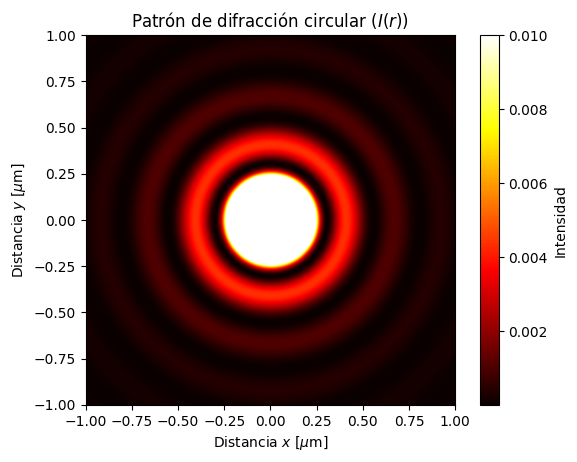

In [81]:
#Intensidad:
lamb = 500e-9
k= (2*np.pi) / lamb
rmax = 1e-6 #Es un orden más grande
N=400


#Creamos un plano
x=np.linspace(-rmax,rmax,N)
y=np.linspace(-rmax,rmax,N)

X, Y =np.meshgrid(x,y)

#La distancia es:
R=np.sqrt(X**2+Y**2)
kr = k * R

J1_vals = np.array([J_simp(1, val) for val in kr.ravel()]).reshape(kr.shape)

I = (J1_vals / kr)**2

plt.imshow(I, extent=[-1, 1, -1, 1], cmap='hot', vmax=0.01)

plt.title('Patrón de difracción circular ($I(r)$)')
plt.xlabel('Distancia $x$ [$\mu$m]')
plt.ylabel('Distancia $y$ [$\mu$m]')
plt.colorbar(label='Intensidad')
plt.show()

### **3. Capacidad calorífica de un sólido** 
(a) Escribe una función Cv(T) que calcule la CV para un valor dado de temperatura,
de una muestra que consta de 1000 centímetros cubicos de aluminio sólido, con
densidad numérica de $\rho = 6.022 × 1028 m−3$ y una temperatura de Debye de $\theta_D = 428 K$. Utiliza la **cuadratura gaussiana** para evaluar la integral, con N = 50 puntos muestra.

In [82]:
import numpy as np
import matplotlib.pyplot as plt


In [104]:
#Primero las constantes:
V = 1000 #Volumen en cm^3
ro = 6.022e28 #Densidad en m^-3
TDebye= 428 #Temperatura de Debye em K
kb = 1.380e-23 #Constante de Boltzmann

N=50 #Muestras

#Ahora definimos la funcion Cv
def Cv(T):

#Los límites de la integral de arriba
    a = 0.0
    b=TDebye/T

    z,w = np.polynomial.legendre.leggauss(N) #Pesos para la cuadratura

    #Para el intervalo a,b debemos de hacer: (Ya que no va de -1 a 1)
    x =(b-a)*z/2 + (b+a)/2
    peso = w * (b-a)/2

    #Ahora la funcion que vamos a integrar, luego la integral.
    f= (x**4 * np.exp(x)) / (np.exp(x)-1)**2

    integral = np.sum(peso*f) #Usamos la cuadratura

    return 9*V*ro*kb*(T/TDebye)**3 *integral






In [105]:
print (Cv(200))

2003945685.8889463


(b) Usa tu funcion para hacer una gráfica de la capacidad calorífica en funcion de la temperatura desde T = 5 K hasta T = 500 K.

In [106]:
import numpy as np
import matplotlib.pyplot as plt

In [119]:
#Usamos la funcion anterior xd

#Primero las constantes:
V = 1000 #Volumen en cm^3
ro = 6.022e28 #Densidad en m^-3
TDebye= 428 #Temperatura de Debye em K
kb = 1.380e-23 #Constante de Boltzmann

N=50 #Muestras

#Ahora definimos la funcion Cv
def Cv(T):

#Los límites de la integral de arriba
    a = 0.0
    b=TDebye/T

    z,w = np.polynomial.legendre.leggauss(N) #Puntos y pesos para la cuadratura

    #Para el intervalo a,b debemos de hacer: (Ya que no va de -1 a 1)
    x =(b-a)*z/2 + (b+a)/2
    peso = w * (b-a)/2

    #Ahora la funcion que vamos a integrar, luego la integral.
    f= (x**4 * np.exp(x)) / (np.exp(x)-1)**2

    integral = np.sum(peso*f) #Usamos la cuadratura

    return 9*V*ro*kb*(T/TDebye)**3 *integral

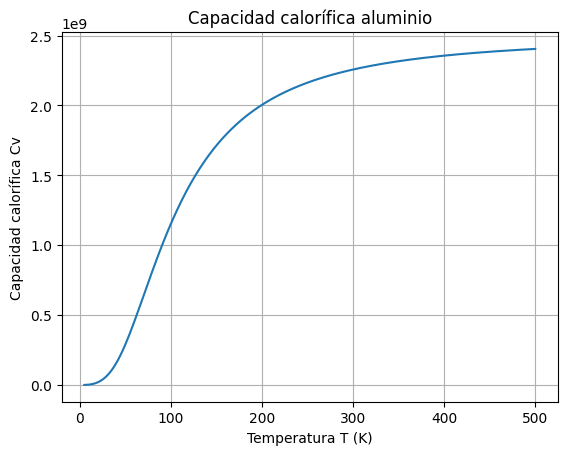

In [122]:
#Ahora la gráfica:


T = np.linspace(5, 500, 200) #Creamos el areglo de 5K a 500K

C = [] #Creamos un arreglo vacío para ir guardando los valores de C

for temp in T:
    C.append(Cv(temp))

C = np.array(C) #Juntamos todo los valores que salieron  para cada T

plt.plot(T, C)
plt.xlabel("Temperatura T (K)")
plt.ylabel("Capacidad calorífica Cv")
plt.title("Capacidad calorífica aluminio")
plt.grid()
plt.show()


### **4. Incertidumbre cuántica en el oscilador armónico** 
(a) Escribe una funcion $H(n,x)$ que calcule $H_n(x)$ dados x y cualquier numero entero 
$n ≥ 0$. Utiliza tu funcion para hacer una gráfica que muestre las funciones de onda del oscilador armonico para n = 0, 1, 2 y 3, todos en el mismo gráfico, en  el rango de x =  4 a x = 4. **Hint: Hay una funcion factorial en el paquete math que calcula el factorial de un numero entero.**

In [123]:
import numpy as np
import matplotlib.pyplot as plt
import math as mt

In [142]:
#Definimos la funcion de hermite con recurrencia

def H(n,x):
    if n == 0:
        return 1.0 #Si n=0, H0 = 1

    if n == 1: 
        return 2*x  #Si n=1, H1 = 2x

    H0 = 1.0
    H1 = 2*x

    for i in range (1, n):
        H2 = 2*x*H1 -2*i*H0
        H0=H1
        H1=H2

    return H1

#Ahora hay que definir la funcion de onda psi

def f_onda(n,x):
    normalizar= 1/ mt.sqrt(2**n * mt.factorial(n) * mt.sqrt(mt.pi))

    return np.exp(-x**2/2) * H (n,x) * normalizar

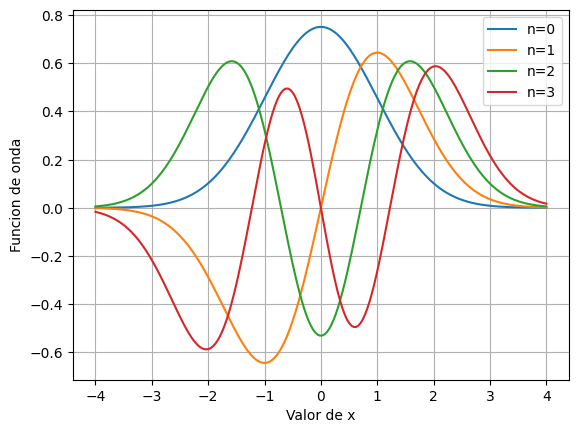

In [146]:
#Ahora la gráfica
x=np.linspace(-4,4,200) #Creamos el arreglo para x de -4 a 4

for n in range (4):
    plt.plot(x, f_onda(n,x), label= f"n={n}")

    plt.xlabel ("Valor de x")
    plt.ylabel ("Funcion de onda")

    plt.grid(True)
    plt.legend()
    

(b) Haz una grafica aparte, de la función de onda para n = 30 desde x = −10 hasta x = 10 **Hint: si tu programa tarda demasiado en ejecutarse en este caso, entonces esta haciendo mal el cálculo; el programa debería tardar aproximadamente un segundo en ejecutarse**

C:\Users\franq\AppData\Local\Temp\ipykernel_11220\2095891143.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


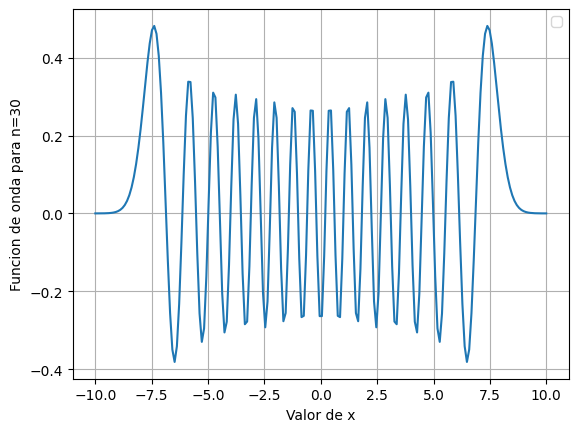

In [149]:
#Usamos el código anterior de la gráfica y lo modificamos ligeramente
x=np.linspace(-10,10,200)

plt.plot(x, f_onda(30,x))

plt.xlabel ("Valor de x")
plt.ylabel ("Funcion de onda para n=30")

plt.grid(True)
plt.legend()

(c) La incertidumbre cuantica de una partícula en el n-ésimo nivel de un oscilador armónico cuántico se puede cuantificar mediante su *media cuadrática* $\sqrt{\langle x^2 \rangle} $ donde: 

$$
\langle x^2 \rangle = \int_{-\infty}^{\infty} x^2 | \psi_n (x)|^2 dx
$$

Escribe un programa que evalue esta integral usando la cuadratura gaussiana en 100 puntos y luego calcula la incertidumbre (es decir, la posicion media cuadrática  de la partícula) para un valor dado de n. Utiliza tu programa para calcular la incertidumbre para n = 5. Deberías obtener una respuesta cercana a $\langle x^2 \rangle =2.3$


In [150]:
import numpy as np
import math as mt

In [166]:
#Ponemos los 100 puntos que queremos
N = 100

z,w = np.polynomial.legendre.leggauss(N) #Puntos y pesos para la cuadratura

#Queremos que sea en un intervalo distinto de -1 a 1, como -20 a 20 digamos
a = -20.0
b= 20.0

x =(b-a)*z/2 + (b+a)/2
dx = (b-a)/2

#Queremos que sea para n=5
n=5

#Ahora va la integral
dentintegral = x**2 * (np.abs(f_onda(n,x))**2) #La parte dentro de la integral pues
integral = np.sum(w * dentintegral) * dx

#Finalmente, sacamos la raíz de esto

incerti = np.sqrt(integral)


print(f"Incertidumbre para n={n} es:", incerti)

Incertidumbre para n=5 es: 2.345083935137998


### **5. Atracción gravitacional de una lámina uniforme** 
(a) Considera la fuerza gravitacional debida a la placa que siente una masa puntual
de 1 kg a una distancia z del centro del cuadrado, en direccion perpendicular a la lámina, como se muestra en la figura. Demuestra que la componente de la fuerza a lo largo del eje z es:

$$
F_z = G \sigma z \int \int_{-L/2}^{L/2} \frac{dxdy}{(x^2+y^2+z^2)^{3/2}}
$$

Donde  $G = 6.674 × 10^{−11} m^3 kg^{-1} s^{-2}$
es la constante gravitacional de Newton y $\sigma$ es la masa por unidad de área de la hoja. 


Primero, la densidad de masa está dada por:
$\sigma = \frac{M}{L^2} $

Lo calculamos usando los datos que tenemos, M=10000 kg y L=10m, de forma que obtenemos:

$$\sigma = \frac{10000}{10^2} = 100 kg/m^2$$

Ahora, consideremos un elemento de área $dA = dxdy$, entonces su masa sería $dm=\sigma dxdy$

Además, la distancia es: $r = \sqrt{x^2 +y^2 + z^2}$

Seguimos por usar la ley de gravitación universal de Newton, de forma que:

$$
F = \frac{G m_1 m}{r^2} \Rightarrow dF = \frac{G m_1 dm}{r^2} = G\frac{\sigma dx dy} {x^2+y^2+z^2}
$$


Para la componente en z, hay que multiplicar por un coseno, usando que $cos\theta = \frac{z}{x^2+y^2+z^2}$

Por lo tanto:
$$
dF_z cos\theta = G\frac{\sigma dx dy} {x^2+y^2+z^2} \frac{z}{x^2+y^2+z^2}
$$ $\\$

$$dF_z =  Gz\sigma \frac{dx dy} {(x^2+y^2+z^2)^{3/2}}$$

$$\\$$


Integramos esto para x e y, obtenemos lo siguiente:

$$F_z = Gz\sigma \int \int_{-L/2}^{L/2} \frac{dxdy}{(x^2+y^2+z^2)^{3/2}}$$

(b) Escribe un programa para calcular y graficar la fuerza en función de z de z = 0 hasta z = 10 m. Para la integral doble utiliza la cuadratura Gaussiana (doble)

In [ ]:
import numpy as np
import math as mt
import matplotlib.pyplot as plt

C:\Users\franq\AppData\Local\Temp\ipykernel_23044\941596477.py:44: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


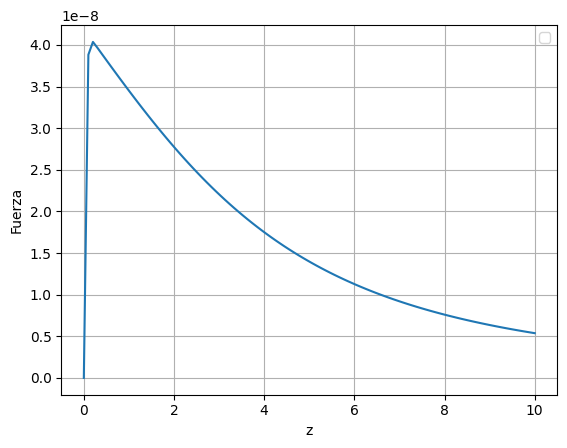

In [48]:
#Definimos cconstantes

G = 6.674e-11
M=10000
L=10
sigma = M/ L**2

N=100 
n,w = np.polynomial.legendre.leggauss(N)

#Queremos que la suma sea de -L/2 a L/2, así que transformamos el intervalo -1 a 1
a= -L/2
b=L/2

x =(b-a)*n/2 + (b+a)/2
y =(b-a)*n/2 + (b+a)/2
peso = w * (b-a)/2
dx = dy = (b-a)/2


z=np.linspace(0,10,100) #Creamos el arreglo para z
fuerzaZ=[]

#Calculamos la integral 
for k in z:
    integral=0 

    for i in range(N):
        for j in range(N):
            integral += w[i] * w[j] /(x[i]**2 + y[j]**2 + k**2)**(3/2)

    fuerza= G*sigma*k * integral *dx*dy

    fuerzaZ.append(fuerza)

#Ahora la grafica

plt.plot(z, fuerzaZ)

plt.xlabel ("z")
plt.ylabel ("Fuerza")

plt.grid(True)
plt.legend()




(c) Deberías ver una curva suave, excepto en valores muy pequeños de z, donde la
fuerza debería caer repentinamente a cero. Esta cíada no es un efecto real, sino un artefacto de la forma en que hemos realizado el calculo. Explica brevemente de donde viene este artefacto y sugiere una estrategia para eliminarlo, o al menos disminuir su tamaño. 

Pasa que los nodos de Gauss no incluyen el centro cuando se usan dos puntos, así que cuando z es muy pequeño, la función queda alrededor del origen. Podríamos aumentar los nodos para intentar que se haga más pequeño este artefacto

### **6. Rejillas de difracción** 
(a) Considera una rejilla con funcion de transmisión $ q(u) = sin^2 \alpha u $. ¿Cual es la separación de las “rendijas” en esta rejilla, expresada en términos de $\alpha$?

Los centros de las rendijas suceden cuando el argumento del seno es multiplo de $\pi$, entonces tendríamos $\alpha u = n\pi$, así que la separación es la distancia que hay entre los máximos, es decir, $d=\frac{\pi}{\alpha}$ $\\$

Por lo que si usamos la separación que nos dan y despejamos $\alpha$, esto es:

$$ \alpha = \frac{\pi}{20\times 10^{-6}} = 15.707 \times 10^4$$

(b) Escribe una funcion en Python q(u) que devuelva la transmisión (i.e $q(u) =
sin^2 \alpha u$) para una rejilla cuyas rendijas tienen una separacion 20µ

In [51]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

In [ ]:
#Constantes
d = 20e-6
alpha = np.pi / d

def q(u):
    return np.sin(alpha * u)**2


(c) Utiliza tu funcion en un programa para calcular y representar gráficamente la 
intensidad del patron de difracción producido por dicha rejilla con diez rendijas 
en total, si la luz incidente tiene una longitud de onda λ = 500 nm. Supongamos
que la lente tiene una distancia focal de 1 metro y la pantalla tiene 10 cm de ancho.
Puedes utilizar cualquier metodo que creas apropiado para hacer la integral. Una
vez que hayas hecho tu eleccion, también deberás decidir la cantidad de puntos
de muestra que utilizaras. ¿Qué criterios influyen en esta decisión? 

In [ ]:
import numpy as np
import scipy

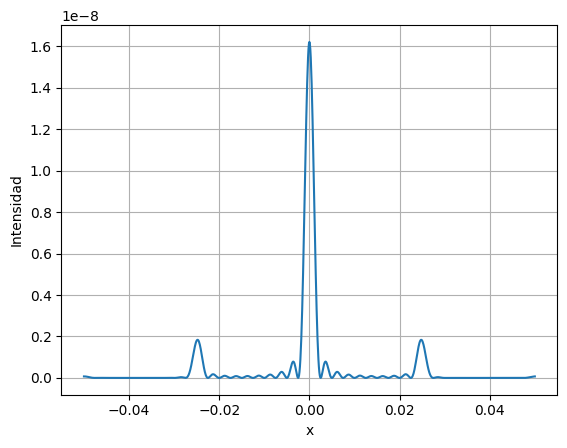

In [72]:
#Constantes
d = 20e-6
alpha = np.pi / d
lam=500e-9
f = 1
w = 10*d

def q(u):
    return np.sin(alpha * u)**2

N = 1000
u= np.linspace(-w/2, w/2, N)

raiz= np.sqrt(q(u))

#posiciones
x = np.linspace(-0.05,0.05, 1001)
I = np.zeros(len(x)) #Arreglo de ceros para la intensidad

#Integral

for i in range(len(x)):
    integral = scipy.integrate.simpson(raiz * np.exp((1j*2*np.pi*x[i]*u)/(lam*f)), x=u) #Usé simpson porque queda mejor con funciones trigonometricas
    I[i] = np.abs(integral)**2

    

plt.plot(x, I)

plt.xlabel ("x")
plt.ylabel ("Intensidad")

plt.grid(True)


(d) Crea una visualizacion de como se vería el patron de difracción en la pantalla usando un grafico de densidad.

In [71]:
import numpy as np
import matplotlib.pyplot as plt


Text(0.5, 0, 'x')

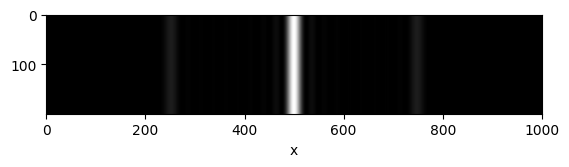

In [103]:
#grafica
pantalla = np.tile(I, (200, 1)) #Esto me lo robé de chatgpt:(

plt.imshow(pantalla, cmap='gray')
plt.xlabel ("x")


(e) Modifica aun m ´ as su programa para crear im ´ agenes de los patrones de difracci ´ on´
producidos por rejillas con los siguientes perfiles: $\\$
i. Un perfil de transmision que obedece a  $$q(u) = sin^2 \alpha u * sin^2 \beta u$$
Con $\alpha$ y w (ancho total de rejilla) igual que antes; y $\beta =\alpha/2$

$\\$ ii. Dos rendijas ”cuadradas”, es decir, rendijas con 100% de transmision a través
de la rendija y 0% de transmision en cualquier otro lugar. Calcule el patrón
de difraccion para rendijas no idénticas, una de 10 µm de ancho y la otra de
20 µm de ancho, con un espacio de 60 µm entre las dos.


In [ ]:
import numpy as np
import scipy
import matplotlib.pyplot as plt

Text(0.5, 0, 'x')

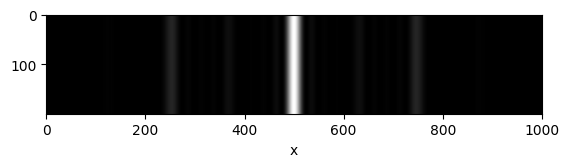

In [110]:
#Constantes
d = 20e-6
alpha = np.pi / d
lam=500e-9
f = 1
w = 10*d
beta=alpha/2

def q(u):
    return (np.sin(alpha * u)**2)*(np.sin(beta * u)**2)

N = 1000
u= np.linspace(-w/2, w/2, N)

raiz= np.sqrt(q(u))

#posiciones
x = np.linspace(-0.05,0.05, 1001)
I = np.zeros(len(x)) #Arreglo de ceros para la intensidad

#Integral

for i in range(len(x)):
    integral = scipy.integrate.simpson(raiz * np.exp((1j*2*np.pi*x[i]*u)/(lam*f)), x=u) #Usé simpson porque queda mejor con funciones trigonometricas
    I[i] = np.abs(integral)**2

    #grafica
pantalla = np.tile(I, (200, 1))

plt.imshow(pantalla, cmap='gray')
plt.xlabel ("x")